# 02 · Modelling — Used Car Pricing Engine (Version 2)

Version 1 used linear models: about 7.6% average test error, U-shaped errors across price, and expensive cars priced too low.
This notebook walks through Version 2 with the same functions as `python -m src.train`:

1. compare linear models with two gradient-boosting libraries (cross-validation on training rows only)
2. errors per price band, **before** (linear) and **after** (boosting)
3. price ranges from the model: conformalized quantile regression
4. one-time test evaluation
5. per-car explanations (SHAP) and the depreciation behaviour

**Rules:** the test set is split off first and used once, at the end. Every learned step lives inside the pipelines, so in each CV fold it learns from that fold's training part only.

In [1]:
import sys, pathlib, json, math
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

from src.cleaning import load_raw, clean
from src.train import (split_data, compare_models, select_model, band_edges_from, band_labels, errors_by_band,
                       quantile_model, coverage_table, CV)
from src.model import PricingModel, assign_band, conformity_scores, conformal_correction, QUANTILES
from src.evaluate import regression_metrics
from src.features import build_tree_pipeline
from src.config import METADATA_PATH
from src.plot_style import apply_style, BLUE, ORANGE, AQUA, INK_2

apply_style()
pd.set_option("display.width", 160)
df = clean(load_raw())
X_train, X_test, y_train, y_test = split_data(df)
edges = band_edges_from(y_train)
print(f"train {len(X_train):,} | test {len(X_test):,} (locked away)")
print("price bands (training-price quintiles):", band_labels(edges))

train 11,393 | test 2,849 (locked away)
price bands (training-price quintiles): ['under €11,490', '€11,490–€15,500', '€15,500–€18,763', '€18,763–€22,990', 'over €22,990']


## 1. The tree pipeline

Same cleaning and feature ideas as Version 1, with two changes for boosting:
- categories become **integer codes** (`OrdinalEncoder`) that LightGBM splits on directly, so each category stays one feature (useful for explanations)
- a `TreeModel` wrapper adds **monotonic constraints**: the estimated price may only fall as `km` or `age` rise.

In [2]:
from lightgbm import LGBMRegressor
demo = build_tree_pipeline(LGBMRegressor(n_estimators=10, verbose=-1)).fit(X_train, y_train)
Xt = demo.regressor_.named_steps["prep"].transform(X_train.head(3))
print(Xt.shape[1], "model inputs (no data rows are printed in this published notebook):")
pd.Series(Xt.columns).str.split("__").str[0].value_counts().rename("columns per input group")

102 model inputs (no data rows are printed in this published notebook):


equip    83
cat       9
num       8
km        2
Name: columns per input group, dtype: int64

## 2. Compare models with cross-validation (training rows only)

Ridge and Lasso get small grids; HistGradientBoosting and LightGBM each try 15 random settings. All are scored by 5-fold CV MAPE.
The selection rule was written **before** the tuning results were seen (see `select_model`).

In [3]:
table, searches = compare_models(X_train, y_train)
selected = select_model(table)
print(select_model.__doc__)
print("Selected:", selected)
table.round(3)

Selection rule, fixed BEFORE tuning results were seen:

1. lowest cross-validated MAPE wins;
2. but if the best boosting model is within one fold-std of LightGBM, take
   LightGBM: it is faster and has exact per-car explanations built in
   (pred_contrib = TreeSHAP), so the app needs no extra explanation library.

Selected: lightgbm


,family,cv_mape_pct,cv_mape_std,cv_mae_eur,cv_r2,search_minutes,best_params
model,,,,,,,
hist_gradient_boosting,boosting,5.233,0.090,952.682,0.957,3.581,"{""min_samples_leaf"": 10, ""max_leaf_nodes"": 63,..."
lightgbm,boosting,5.278,0.099,965.113,0.955,1.107,"{""reg_lambda"": 1.0, ""num_leaves"": 63, ""n_estim..."
lasso,linear,7.826,0.249,1459.509,0.907,0.124,"{""alpha"": 0.0001}"
ridge,linear,7.834,0.245,1460.314,0.908,0.127,"{""alpha"": 1}"


**Reading the table**
- Both boosting libraries beat the best linear model by about 2.5 percentage points of MAPE (roughly a third less error).
- HistGradientBoosting is marginally ahead of LightGBM, but the gap is smaller than one fold-to-fold standard deviation, so it is noise.
  Under the pre-set rule LightGBM is selected. It is also about 3× faster to tune and has exact SHAP explanations built in.

## 3. What does the monotonic constraint cost?

Same tuned LightGBM settings, with and without the constraint, compared on out-of-fold predictions.

In [4]:
point = searches[selected].best_estimator_
free = clone(point).set_params(regressor__model__monotone=False)
oof_point = cross_val_predict(point, X_train, y_train, cv=CV, n_jobs=2)
oof_free = cross_val_predict(free, X_train, y_train, cv=CV, n_jobs=2)
pd.DataFrame({"constrained": regression_metrics(y_train, oof_point),
              "unconstrained": regression_metrics(y_train, oof_free)}).T.round(3)

,r2,mae_eur,mape_pct,median_ape_pct,n
constrained,0.955,965.111,5.278,3.734,11393.0
unconstrained,0.956,956.728,5.236,3.698,11393.0


The constraint barely changes accuracy (see the `mape_pct` column), and it guarantees that the depreciation chart never shows a car getting more expensive with more km or age.

## 4. Errors per price band: before (linear) and after (LightGBM), cross-validation

In [5]:
best_linear = table[table.family == "linear"].index[0]
oof_linear = cross_val_predict(searches[best_linear].best_estimator_, X_train, y_train, cv=CV, n_jobs=2)
cv_before = errors_by_band(y_train, oof_linear, edges)
cv_after = errors_by_band(y_train, oof_point, edges)
pd.concat({"linear (before)": cv_before, "LightGBM (after)": cv_after}, axis=1).round(2)

linear (before)                                   LightGBM (after)                                  
                              n mape_pct  mae_eur median_bias_pct                n mape_pct  mae_eur median_bias_pct
band                                                                                                                
under €11,490              2275     8.89   823.66            3.54             2275     6.04   548.63            0.02
€11,490–€15,500            2263     7.49  1024.87           -0.28             2263     5.21   714.17            0.39
€15,500–€18,763            2298     6.70  1140.89           -0.15             2298     4.83   823.58           -0.32
€18,763–€22,990            2278     6.42  1336.01            0.17             2278     4.30   889.56           -0.52
over €22,990               2279     9.63  2970.52           -2.74             2279     6.01  1848.27           -1.36

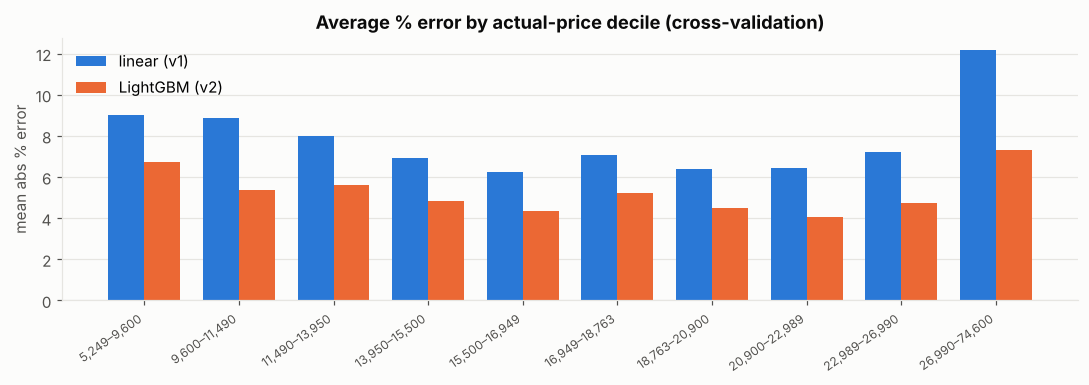

,linear,lightgbm
"5,249–9,600",9.01,6.72
"9,600–11,490",8.85,5.37
"11,490–13,950",7.99,5.63
"13,950–15,500",6.93,4.83
"15,500–16,949",6.24,4.36
"16,949–18,763",7.09,5.24
"18,763–20,900",6.39,4.51
"20,900–22,989",6.46,4.07
"22,989–26,990",7.20,4.74
"26,990–74,600",12.16,7.32


In [6]:
def decile_errors(y, pred):
    y, pred = np.asarray(y, float), np.asarray(pred, float)
    dec = pd.qcut(y, 10)
    ape = pd.Series(np.abs(pred - y) / y * 100)
    out = ape.groupby(dec, observed=True).mean()
    out.index = [f"{int(i.left):,}–{int(i.right):,}" for i in out.index]
    return out

def decile_chart(y, before, after, title, path=None):
    d_b, d_a = decile_errors(y, before), decile_errors(y, after)
    x = np.arange(len(d_b)); w = 0.38
    fig, ax = plt.subplots(figsize=(10, 3.6))
    ax.bar(x - w/2, d_b, w, color=BLUE, label="linear (v1)")
    ax.bar(x + w/2, d_a, w, color=ORANGE, label="LightGBM (v2)")
    ax.set_xticks(x, d_b.index, rotation=35, ha="right", fontsize=8)
    ax.set(title=title, ylabel="mean abs % error"); ax.grid(axis="x", visible=False); ax.legend()
    plt.tight_layout()
    if path: plt.savefig(path, dpi=110)
    plt.show()
    return pd.DataFrame({"linear": d_b, "lightgbm": d_a}).round(2)

decile_chart(y_train, oof_linear, oof_point, "Average % error by actual-price decile (cross-validation)")

**Before vs after (cross-validation):**
- Errors fall in **every** band, and most at the two extremes where the linear model was weakest.
- The linear model's systematic bias at the extremes (cheap cars over-estimated, expensive cars under-estimated) almost disappears; see `median_bias_pct`.
- A milder U-shape remains: the cheapest and most expensive cars are still the hardest, in % terms.

## 5. Price ranges from the model: conformalized quantile regression (CQR)

**Why this method.** Two options were considered:
- *Quantile regression alone:* two extra LightGBM models predict the 10th and 90th percentile, so each car gets its own width. But nothing guarantees 80% coverage, and boosted quantile models tend to be over-confident.
- *Plain conformal intervals:* guaranteed coverage, but the same % width for every car. That is essentially what Version 1 did.

CQR combines them: quantile models give the per-car shape, then a conformal correction learned on out-of-fold predictions widens every range just enough to reach 80%.
The correction is computed **per price band** ("Mondrian" conformal), so the 80% holds inside each band, not only on average.

In [7]:
params = {k.split("__")[-1]: v for k, v in searches[selected].best_params_.items()}
lower_u, upper_u = quantile_model(params, QUANTILES[0]), quantile_model(params, QUANTILES[1])
oof_lo = np.minimum(cross_val_predict(lower_u, X_train, y_train, cv=CV, n_jobs=2), oof_point)
oof_hi = np.maximum(cross_val_predict(upper_u, X_train, y_train, cv=CV, n_jobs=2), oof_point)
print("Raw quantile models, before calibration (out-of-fold):")
coverage_table(y_train, oof_lo, oof_hi, oof_point, edges).round(3)

Raw quantile models, before calibration (out-of-fold):


,by_estimate,by_actual,mean_width_pct,n
band,,,,
all,0.647,0.647,13.290,11393
"under €11,490",0.633,0.604,12.173,2173
"€11,490–€15,500",0.641,0.671,14.190,2415
"€15,500–€18,763",0.660,0.659,12.202,2286
"€18,763–€22,990",0.667,0.677,12.383,2298
"over €22,990",0.634,0.624,15.465,2221


In [8]:
scores = conformity_scores(y_train.to_numpy(float), oof_lo, oof_hi)
oof_band = assign_band(oof_point, edges)
corrections = [conformal_correction(scores[oof_band == b]) for b in range(len(edges) + 1)]
pd.DataFrame({"band (by estimate)": band_labels(edges), "correction (log)": corrections,
              "≈ widening each side": [f"{(math.exp(c) - 1) * 100:+.1f}%" for c in corrections]})

,band (by estimate),correction (log),≈ widening each side
0,"under €11,490",0.018566,+1.9%
1,"€11,490–€15,500",0.021843,+2.2%
2,"€15,500–€18,763",0.012712,+1.3%
3,"€18,763–€22,990",0.013648,+1.4%
4,"over €22,990",0.022467,+2.3%


The raw quantile models are clearly **too narrow** (well under 80% coverage), as expected. The positive corrections widen each range to fix that.

## 6. Final fit and the one-time test evaluation

In [9]:
model = PricingModel(point=clone(point).fit(X_train, y_train),
                     lower=clone(lower_u).fit(X_train, y_train),
                     upper=clone(upper_u).fit(X_train, y_train),
                     band_edges=edges, corrections=corrections)
linear_final = clone(searches[best_linear].best_estimator_).fit(X_train, y_train)
est, low, high = model.predict_range(X_test)
lin_test = linear_final.predict(X_test)
pd.DataFrame({"linear (v1)": regression_metrics(y_test, lin_test),
              "LightGBM (v2)": regression_metrics(y_test, est)}).T.round(3)

,r2,mae_eur,mape_pct,median_ape_pct,n
linear (v1),0.905,1443.879,7.602,5.747,2849.0
LightGBM (v2),0.955,937.637,5.068,3.378,2849.0


In [10]:
pd.concat({"linear (before)": errors_by_band(y_test, lin_test, edges),
           "LightGBM (after)": errors_by_band(y_test, est, edges)}, axis=1).round(2)

linear (before)                                   LightGBM (after)                                  
                              n mape_pct  mae_eur median_bias_pct                n mape_pct  mae_eur median_bias_pct
band                                                                                                                
under €11,490               533     8.59   798.07            3.32              533     5.84   529.69            0.01
€11,490–€15,500             606     7.32  1001.36           -0.43              606     5.14   703.28            0.38
€15,500–€18,763             537     6.10  1038.12            0.03              537     4.49   765.71           -0.65
€18,763–€22,990             580     6.35  1317.08           -0.13              580     4.18   863.88           -0.47
over €22,990                593     9.58  2968.02           -2.14              593     5.69  1771.63           -1.09

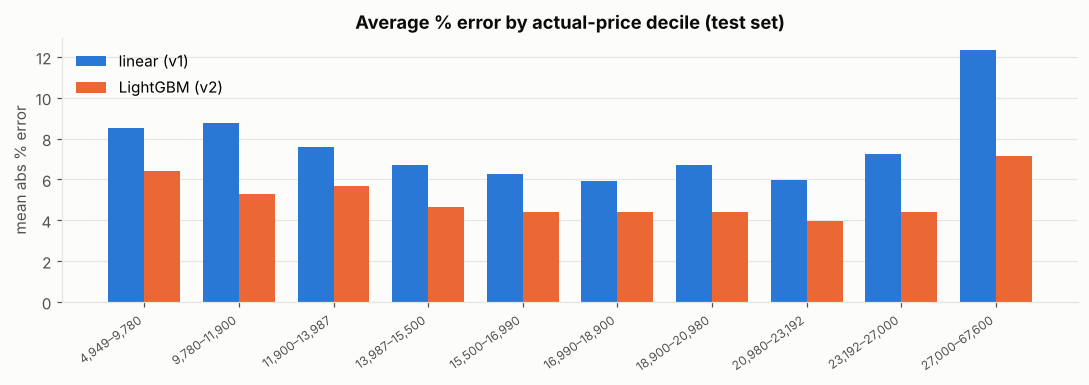

,linear,lightgbm
"4,949–9,780",8.52,6.40
"9,780–11,900",8.78,5.29
"11,900–13,987",7.61,5.67
"13,987–15,500",6.69,4.63
"15,500–16,990",6.27,4.38
"16,990–18,900",5.92,4.38
"18,900–20,980",6.72,4.42
"20,980–23,192",5.96,3.98
"23,192–27,000",7.26,4.41
"27,000–67,600",12.31,7.15


In [11]:
decile_chart(y_test, lin_test, est, "Average % error by actual-price decile (test set)",
             path="../reports/figures/error_by_decile.png")

In [12]:
print("Does the range hold about 80% of real prices on cars it never saw?")
coverage_table(y_test, low, high, est, edges).round(3)

Does the range hold about 80% of real prices on cars it never saw?


,by_estimate,by_actual,mean_width_pct,n
band,,,,
all,0.824,0.824,17.069,2849
"under €11,490",0.809,0.788,16.172,528
"€11,490–€15,500",0.837,0.847,18.862,601
"€15,500–€18,763",0.821,0.834,14.645,549
"€18,763–€22,990",0.828,0.833,15.300,594
"over €22,990",0.823,0.816,20.149,577


In [13]:
# The weakest spot from Version 1: the most expensive cars
mask = y_test.to_numpy() > 40000
for name, p in [("linear (v1)", lin_test), ("LightGBM (v2)", est)]:
    rel = (p[mask] - y_test.to_numpy()[mask]) / y_test.to_numpy()[mask] * 100
    print(f"{name:14s} cars > €40k: n={mask.sum()}, under-estimated {np.mean(rel < 0):.0%}, median bias {np.median(rel):+.1f}%")

linear (v1)    cars > €40k: n=35, under-estimated 66%, median bias -6.3%
LightGBM (v2)  cars > €40k: n=35, under-estimated 66%, median bias -3.5%


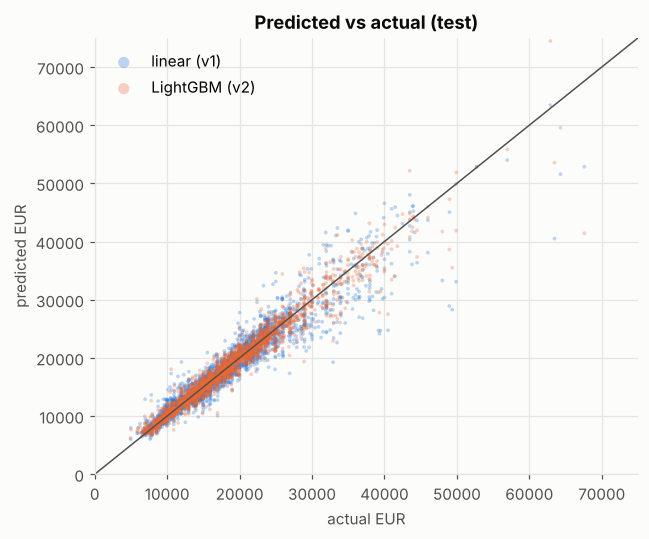

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, lin_test, s=6, alpha=.3, color=BLUE, edgecolors="none", label="linear (v1)")
ax.scatter(y_test, est, s=6, alpha=.3, color=ORANGE, edgecolors="none", label="LightGBM (v2)")
ax.plot([0, 75000], [0, 75000], color=INK_2, linewidth=1)
ax.set(title="Predicted vs actual (test)", xlabel="actual EUR", ylabel="predicted EUR", xlim=(0, 75000), ylim=(0, 75000))
ax.legend(markerscale=3); plt.tight_layout(); plt.savefig("../reports/figures/predicted_vs_actual.png", dpi=110); plt.show()

In [15]:
saved = json.loads(METADATA_PATH.read_text())
assert abs(saved["test_metrics"]["mape_pct"] - regression_metrics(y_test, est)["mape_pct"]) < 1e-9
assert abs(saved["test_range_coverage"][0]["by_estimate"] - coverage_table(y_test, low, high, est, edges).iloc[0]["by_estimate"]) < 1e-9
print("Notebook matches models/metadata.json (same seed, same data).")

Notebook matches models/metadata.json (same seed, same data).


## 7. Why does the model say what it says? SHAP

LightGBM computes exact SHAP values itself (`pred_contrib=True`). For each car they split the log price into a baseline plus one contribution per feature,
so the effects **multiply** to the estimate. Below: which features matter most on average (mean |SHAP| over the test set), then one car.

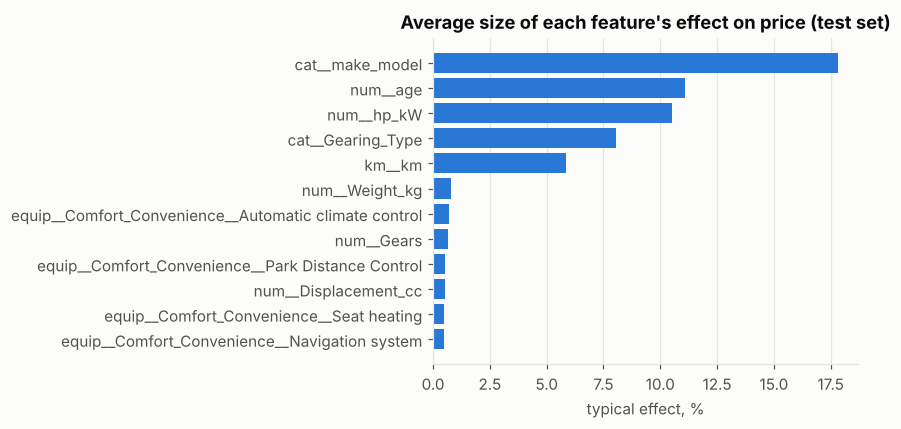

In [16]:
contrib, _ = model.contributions(X_test)
contrib = contrib.drop(columns="bias")
contrib["km__km"] += contrib.pop("km__km_was_imputed")
imp = contrib.abs().mean().sort_values(ascending=False).head(12)
imp_pct = (np.exp(imp) - 1) * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp_pct.index[::-1], imp_pct.values[::-1], color=BLUE)
ax.set(title="Average size of each feature's effect on price (test set)", xlabel="typical effect, %")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

In [17]:
from src.explain import explain_car
car = X_test.iloc[[0]]
ex = explain_car(model, car)
print(f"baseline (average car) €{ex['baseline']:,.0f}  ->  estimate €{ex['estimate']:,.0f}")
ex["reasons"].round(2)

baseline (average car) €16,697  ->  estimate €25,588


,reason,effect_pct,log_effect
0,Age: 0 years,16.61,0.15
1,Model: Audi A3,13.24,0.12
2,"Kilometres: 3,000 km",5.65,0.06
3,Gearbox: Automatic,5.53,0.05
4,Power: 110 kW,4.63,0.05
5,All other features,-0.52,-0.01


## 8. Depreciation behaviour: ask the model

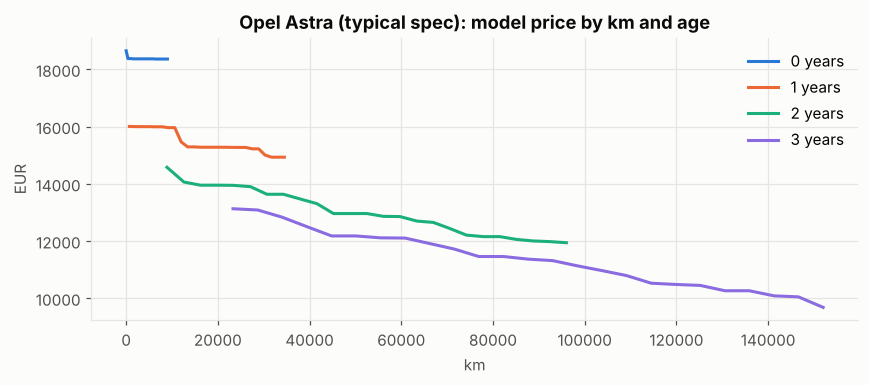

never rises with km: True


In [18]:
from src.predict import depreciation_grid, load_metadata
meta = load_metadata()
car = dict(meta["app"]["defaults"]["Opel Astra"]); car.update(car.pop("equipment"))
grid = depreciation_grid(car, meta["app"]["km_by_age"])
fig, ax = plt.subplots(figsize=(8, 3.6))
for (age, g), color in zip(grid.groupby("age"), [BLUE, ORANGE, AQUA, "#8a6ce0"]):
    ax.plot(g["km"], g["price"], color=color, linewidth=2, label=f"{age:.0f} years")
ax.set(title="Opel Astra (typical spec): model price by km and age", xlabel="km", ylabel="EUR"); ax.legend()
plt.tight_layout(); plt.show()
print("never rises with km:", all((np.diff(g.sort_values("km")["price"]) <= 1e-6).all() for _, g in grid.groupby("age")))

Lines are step-shaped because trees predict in steps. They only ever go down, because of the monotonic constraint.
Each line covers only the km range that real cars of that age have in the training data.

## Summary
See the printed tables above for exact values (the README quotes the same saved results):
- LightGBM cuts test error by about a third versus the linear model, with gains in every price band and the largest at the extremes.
- Under-estimation of very expensive cars is reduced but **not** solved.
- Conformalized quantile ranges reach about 80% coverage on the test set overall and in every band of estimated price.